# 13 · Web 后端进阶（AOP）

来源：[飞书讲义《13-后端Web进阶(AOP)》](https://heuqqdmbyk.feishu.cn/wiki/P0lNwydClihtMukqFsMcpdvQnsh)。整理日期：2026-10-04。

本章承接第 12 章登录认证，学习如何用 Spring AOP 抽取统计耗时、操作日志等通用逻辑：从快速入门和核心概念，到五种通知、通知顺序、切入点表达式，再完成 Tlias 操作日志案例，通过 JWT 与 ThreadLocal 获取当前登录员工。讲义中的 42 段原始代码和 29 张配图已内嵌，离线打开亦可阅读。补充与勘误均单独标注，便于对照原讲义。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 统计业务方法耗时 | AOP 依赖、`RecordTimeAspect` | 调用部门接口，看到业务方法耗时 |
| 2 | 理解代理和切面 | JoinPoint、Advice、Pointcut、Aspect、Target | 能区分匹配条件、通用逻辑和目标对象 |
| 3 | 验证通知类型与顺序 | 五种通知、`@Pointcut`、`@Order` | 对照正常返回与抛出异常两种调用路径 |
| 4 | 选择切入点表达式 | `execution`、`@annotation`、`@LogOperation` | 查询接口与增删改接口按需求分别匹配 |
| 5 | 记录操作日志 | `operate_log`、Mapper、环绕切面 | 类名、方法名、参数、返回值与耗时进入日志表 |
| 6 | 接入当前员工 | `CurrentHolder`、TokenFilter | 日志记录真实员工 ID，请求结束清理上下文 |

### 调用链速览

```text
请求携带 JWT
    -> TokenFilter 验签并读取员工 ID -> CurrentHolder.setCurrentId(id)
    -> Spring 代理 -> @Around 开始计时
    -> @LogOperation 标记的 Controller -> Service -> Mapper
    -> @Around 获取返回值、耗时和当前员工 -> OperateLogMapper.insert(...)
    -> 返回响应 -> Filter 在 finally 中 CurrentHolder.remove()
```

代理调用的要点是“先按切入点选中方法，再按通知类型插入通用逻辑”。`proceed()` 是环绕通知继续执行调用链的入口。

接下来我们进入到AOP的学习。 AOP也是spring框架的第二大核心，我们先来学习AOP的基础。

什么是AOP？

AOP：Aspect Oriented Programming（面向切面编程、面向方面编程），其实说白了，面向切面编程就是面向特定方法编程。

那什么又是面向方法编程呢，为什么又需要面向方法编程呢？

来，我们举个例子做一个说明：

比如，我们这里有一个项目，项目中开发了很多的业务功能。然而有一些业务功能执行效率比较低，执行耗时较长，我们需要针对于这些业务方法进行优化。 那首先第一步就需要定位出执行耗时比较长的业务方法，再针对于业务方法再来进行优化。

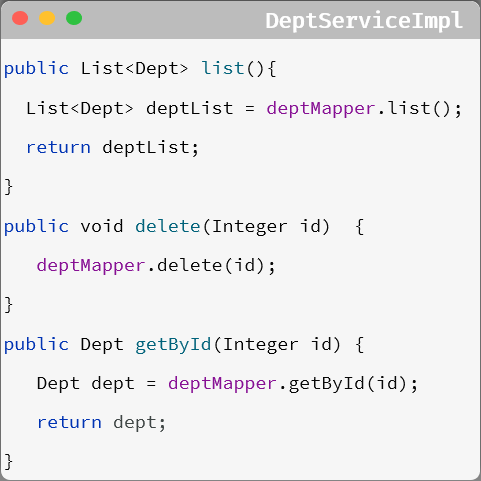

此时我们就需要统计当前这个项目当中每一个业务方法的执行耗时。那么统计每一个业务方法的执行耗时该怎么实现？

可能多数人首先想到的就是在每一个业务方法运行之前，记录这个方法运行的开始时间。在这个方法运行完毕之后，再来记录这个方法运行的结束时间。拿结束时间减去开始时间，不就是这个方法的执行耗时吗。

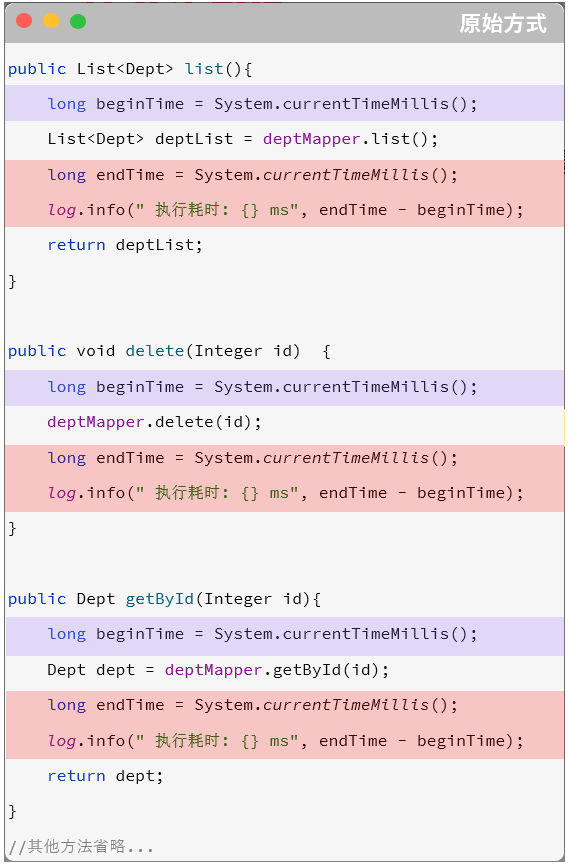

而这个功能如果通过AOP来实现，我们只需要单独定义下面这一小段代码即可，不需要修改原始的任何业务方法即可记录每一个业务方法的执行耗时。

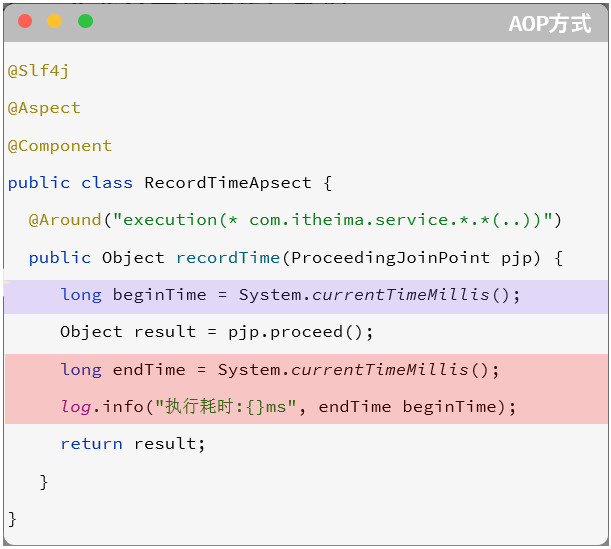

所以，AOP的优势主要体现在以下四个方面：

- 减少重复代码：不需要在业务方法中定义大量的重复性的代码，只需要将重复性的代码抽取到AOP程序中即可。

- 代码无侵入：在基于AOP实现这些业务功能时，对原有的业务代码是没有任何侵入的，不需要修改任何的业务代码。

- 提高开发效率

- 维护方便

> **讲义提示**

> AOP是一种思想，而在Spring框架中，对这种思想进行了实现，那我们要学习的就是Spring AOP。

## AOP基础

### AOP入门

> **补充｜配置与异常路径。** 在本课程使用的 Spring Boot 项目中，引入 `spring-boot-starter-aop` 后通常会自动启用代理支持；切面仍需通过 `@Component` 或 `@Bean` 注册。讲义的计时代码在 `proceed()` 抛出异常时不会执行后面的日志。若要统计成功和失败两条路径，应把计时输出放在 `finally` 中；测量时长优先使用 `System.nanoTime()`，并将 `proceed()` 的结果返回给调用方。

在了解了什么是AOP后，我们下面通过一个快速入门程序，体验下AOP的开发，并掌握Spring中AOP的开发步骤。

- 需求：统计部门管理各个业务层方法执行耗时。

- 原始方式：

在原始的实现方式中，我们需要在业务层的也一个方法执行执行，获取方法运行的开始时间； 然后运行原始的方法逻辑； 最后在每一个方法运行结束时，获取方法运行结束时间，计算执行耗时。

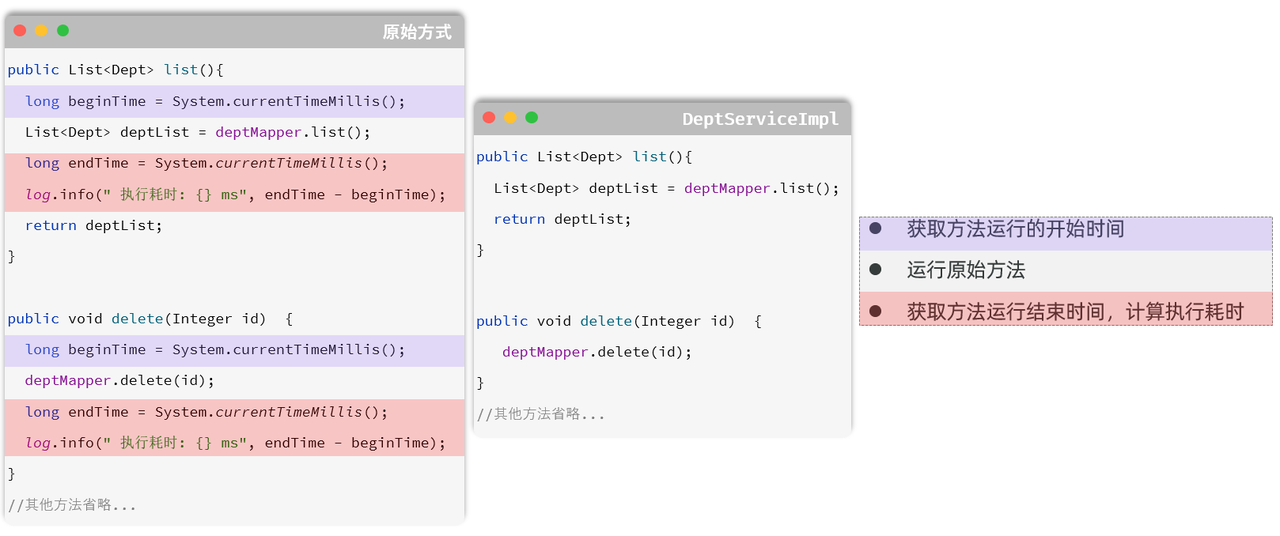

- SpringAOP实现步骤：

为演示方便，可以直接导入资料中提供的springboot-aop-quickstart项目工程

1). 导入依赖：在 pom.xml 文件中导入 AOP 的依赖

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-aop</artifactId>
</dependency>
```

2). 编写AOP程序：针对于特定方法根据业务需要进行编程

```java
@Component
@Aspect //当前类为切面类
@Slf4j
public class RecordTimeAspect {

    @Around("execution(* com.itheima.service.impl.DeptServiceImpl.*(..))")
    public Object recordTime(ProceedingJoinPoint pjp) throws Throwable {
        //记录方法执行开始时间
        long begin = System.currentTimeMillis();

        //执行原始方法
        Object result = pjp.proceed();

        //记录方法执行结束时间
        long end = System.currentTimeMillis();

        //计算方法执行耗时
        log.info("方法执行耗时: {}毫秒",end-begin);
        return result;
    }
}
```

重新启动SpringBoot服务，打开浏览器访问部门管理的功能进行测试：

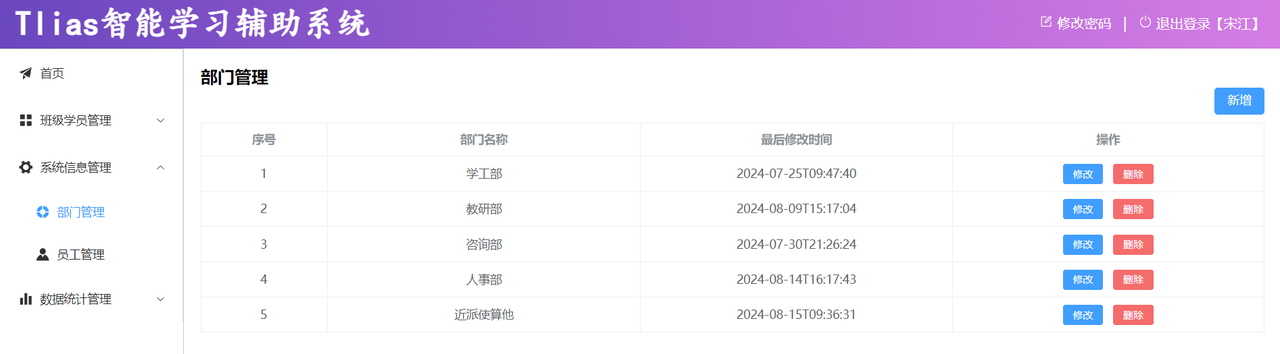

我们可以看到，在控制台中输出了方法的执行耗时：

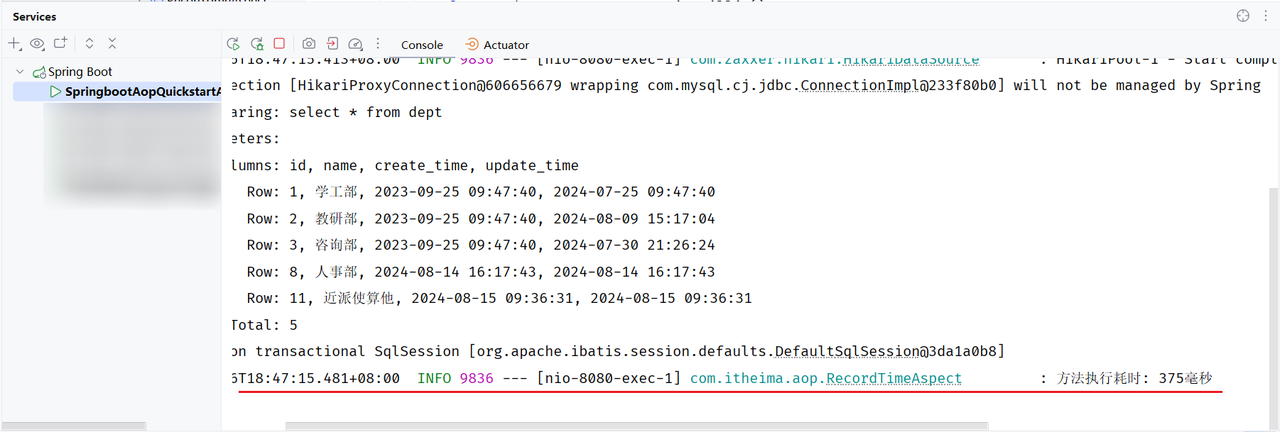

我们通过AOP入门程序完成了业务方法执行耗时的统计，那其实AOP的功能远不止于此，常见的应用场景如下：

- 记录系统的操作日志

- 权限控制

- 事务管理：我们前面所讲解的Spring事务管理，底层其实也是通过AOP来实现的，只要添加@Transactional注解之后，AOP程序自动会在原始方法运行前先来开启事务，在原始方法运行完毕之后提交或回滚事务

这些都是AOP应用的典型场景。

通过入门程序，我们也应该感受到了AOP面向切面编程的一些优势：

- 代码无侵入：没有修改原始的业务方法，就已经对原始的业务方法进行了功能的增强或者是功能的改变

- 减少了重复代码

- 提高开发效率

- 维护方便

### AOP核心概念

> **补充｜Spring AOP 的代理边界。** 本章讨论的是 Spring 管理的 Bean 的方法执行。调用需要经过 Spring 代理才能触发通知；手动 `new` 对象、同一对象内部通过 `this` 调用其他方法，通常会绕过代理。JDK 代理通过接口调用；CGLIB 通过子类增强，无法增强 `final` 或 `private` 方法，也无法为 `final` 类创建子类代理。“无侵入”指通用逻辑可以抽取到切面；使用 `@LogOperation` 仍需给方法添加标记。

通过SpringAOP的快速入门，感受了一下AOP面向切面编程的开发方式。下面我们再来学习AOP当中涉及到的一些核心概念。

- 连接点：JoinPoint，可以被AOP控制的方法（暗含方法执行时的相关信息）

    - 连接点指的是可以被aop控制的方法。例如：入门程序当中所有的业务方法都是可以被aop控制的方法。

    - 在SpringAOP提供的JoinPoint当中，封装了连接点方法在执行时的相关信息。（后面会有具体的讲解）

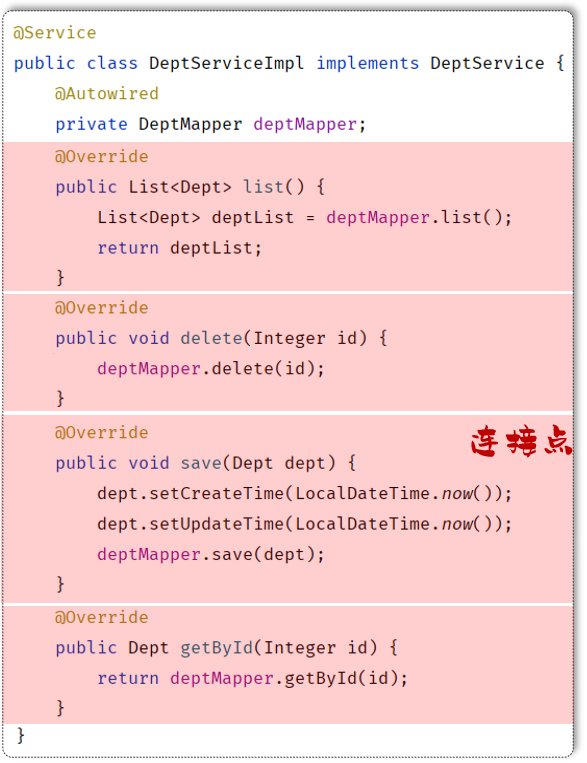

- 通知：Advice，指哪些重复的逻辑，也就是共性功能（最终体现为一个方法）

    - 在入门程序中是需要统计各个业务方法的执行耗时的，此时我们就需要在这些业务方法运行开始之前，先记录这个方法运行的开始时间，在每一个业务方法运行结束的时候，再来记录这个方法运行的结束时间。

    - 是在AOP面向切面编程当中，我们只需要将这部分重复的代码逻辑抽取出来单独定义。抽取出来的这一部分重复的逻辑，也就是共性的功能。

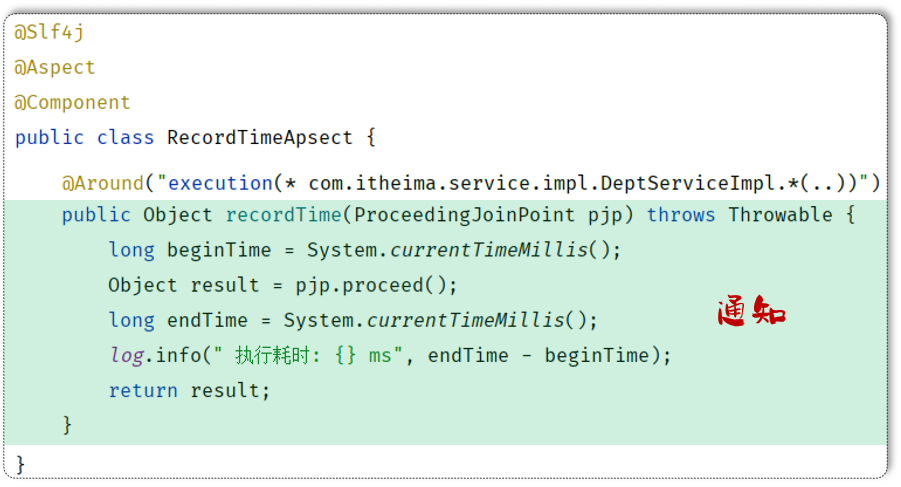

- 切入点：PointCut，匹配连接点的条件，通知仅会在切入点方法执行时被应用。

    - 在通知当中，我们所定义的共性功能到底要应用在哪些方法上？此时就涉及到了切入点pointcut概念。切入点指的是匹配连接点的条件。通知仅会在切入点方法运行时才会被应用。

    - 在aop的开发当中，我们通常会通过一个切入点表达式来描述切入点(后面会有详解)。

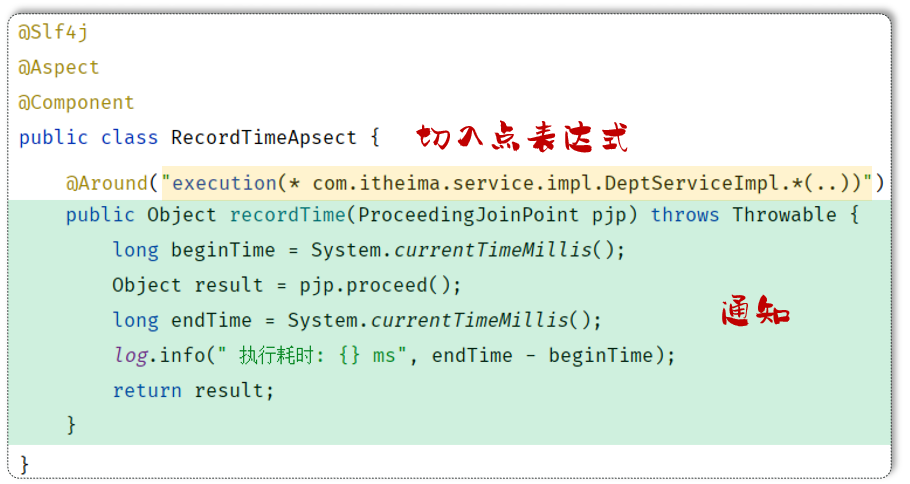

    - 假如：切入点表达式改为DeptServiceImpl.list()，此时就代表仅仅只有list这一个方法是切入点。只有list()方法在运行的时候才会应用通知。

- 切面：Aspect，描述通知与切入点的对应关系（通知+切入点）

当通知和切入点结合在一起，就形成了一个切面。通过切面就能够描述当前aop程序需要针对于哪个原始方法，在什么时候执行什么样的操作。

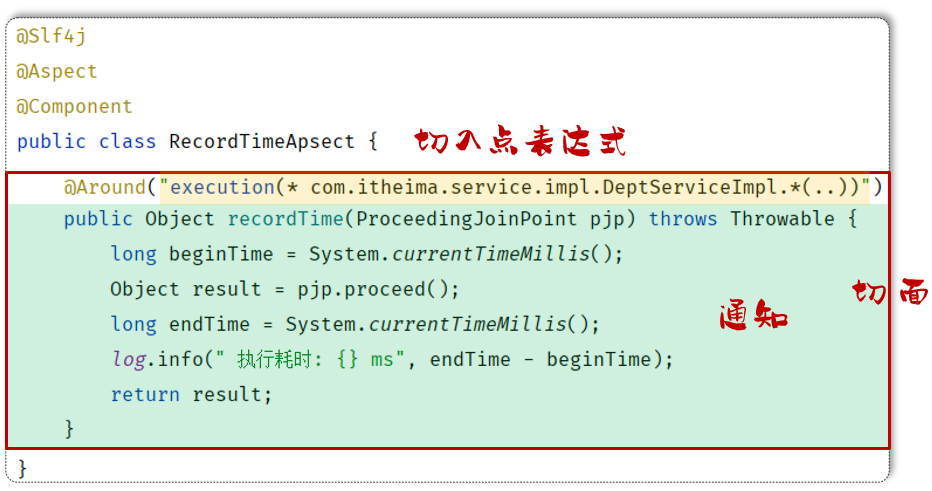

而切面所在的类，称之为切面类（被@Aspect注解标识的类）。

- 目标对象：Target，通知所应用的对象

目标对象指的就是通知所应用的对象，我们就称之为目标对象。

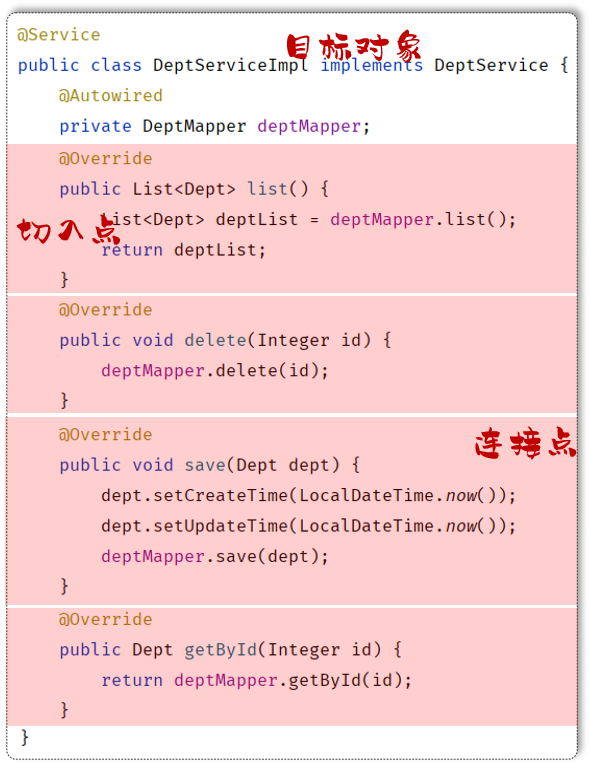

AOP的核心概念我们介绍完毕之后，接下来我们再来分析一下我们所定义的通知是如何与目标对象结合在一起，对目标对象当中的方法进行功能增强的。

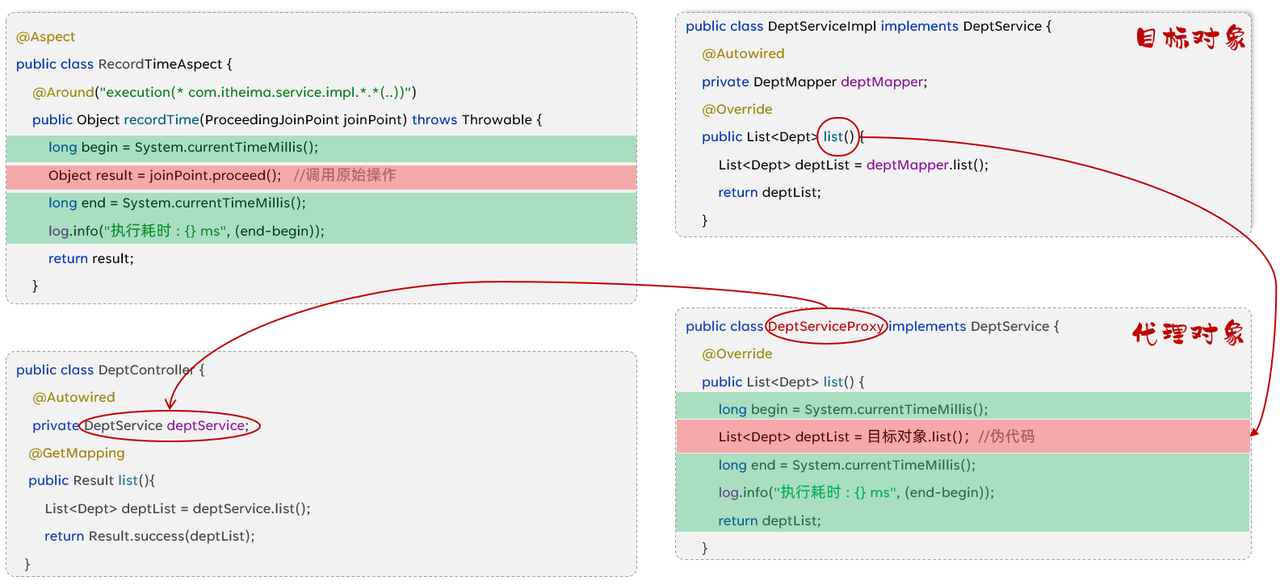

Spring的AOP底层是基于动态代理技术来实现的，也就是说在程序运行的时候，会自动的基于动态代理技术为目标对象生成一个对应的代理对象。在代理对象当中就会对目标对象当中的原始方法进行功能的增强。

> **讲义提示**

> SpringAOP 旨在管理bean对象的过程中，主要通过底层的动态代理机制，对特定的方法进行编程 。

## AOP进阶

AOP的基础知识学习完之后，下面我们对AOP当中的各个细节进行详细的学习。主要分为4个部分：

1. 通知类型

1. 通知顺序

1. 切入点表达式

我们先来学习第一部分通知类型。

### 通知类型

> **补充｜返回与异常语义。** `@After` 相当于退出时的清理逻辑，正常和异常退出都会触发；`@AfterReturning` 只匹配正常返回，`@AfterThrowing` 只匹配抛出的异常。`@Around` 中写在 `proceed()` 后面的普通语句不会自动变成 `finally`。若捕获异常，应保留原异常并继续抛出，避免让调用方误以为业务成功。`@AfterReturning` 可读取返回值；直接替换调用方收到的返回值应使用环绕通知。

在入门程序当中，我们已经使用了一种功能最为强大的通知类型：Around环绕通知。

```java
@Component
@Aspect //当前类为切面类
@Slf4j
public class TimeAspect {

    @Around("execution(* com.itheima.service.impl.DeptServiceImpl.*(..))")
    public Object recordTime(ProceedingJoinPoint pjp) throws Throwable {
        //记录方法执行开始时间
        long begin = System.currentTimeMillis();
        //执行原始方法
        Object result = pjp.proceed();
        //记录方法执行结束时间
        long end = System.currentTimeMillis();
        //计算方法执行耗时
        log.info("方法执行耗时: {}毫秒",end-begin);
        return result;
    }
}
```

只要我们在通知方法上加上了@Around注解，就代表当前通知是一个环绕通知。

**Spring AOP 通知类型**

| 通知注解 | 讲义说明 |
| --- | --- |
| @Around | 环绕通知，此注解标注的通知方法在目标方法前、后都被执行 |
| @Before | 前置通知，此注解标注的通知方法在目标方法前被执行 |
| @After | 后置通知，此注解标注的通知方法在目标方法后被执行，无论是否有异常都会执行 |
| @AfterReturning | 返回后通知，此注解标注的通知方法在目标方法后被执行，有异常不会执行 |
| @AfterThrowing | 异常后通知，此注解标注的通知方法发生异常后执行 |

下面我们通过代码演示，来加深对于不同通知类型的理解：

```java
@Slf4j
@Component
@Aspect
public class MyAspect1 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(JoinPoint joinPoint){
        log.info("before ...");

    }

    //环绕通知
    @Around("execution(* com.itheima.service.*.*(..))")
    public Object around(ProceedingJoinPoint proceedingJoinPoint) throws Throwable {
        log.info("around before ...");

        //调用目标对象的原始方法执行
        Object result = proceedingJoinPoint.proceed();
        
        //原始方法如果执行时有异常，环绕通知中的后置代码不会在执行了
        
        log.info("around after ...");
        return result;
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(JoinPoint joinPoint){
        log.info("after ...");
    }

    //返回后通知（程序在正常执行的情况下，会执行的后置通知）
    @AfterReturning("execution(* com.itheima.service.*.*(..))")
    public void afterReturning(JoinPoint joinPoint){
        log.info("afterReturning ...");
    }

    //异常通知（程序在出现异常的情况下，执行的后置通知）
    @AfterThrowing("execution(* com.itheima.service.*.*(..))")
    public void afterThrowing(JoinPoint joinPoint){
        log.info("afterThrowing ...");
    }
}
```

重新启动SpringBoot服务，进行测试：

1). 没有异常情况下：

使用 Apifox 测试查询所有部门数据

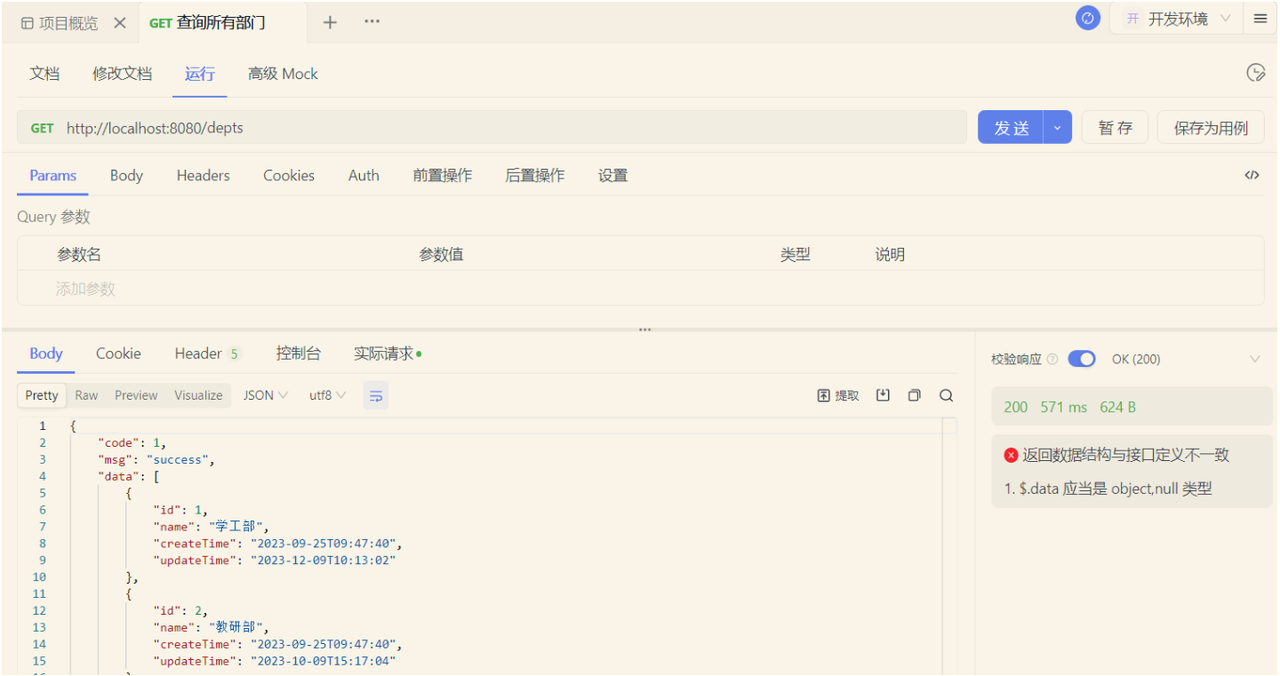

查看idea中控制台日志输出：

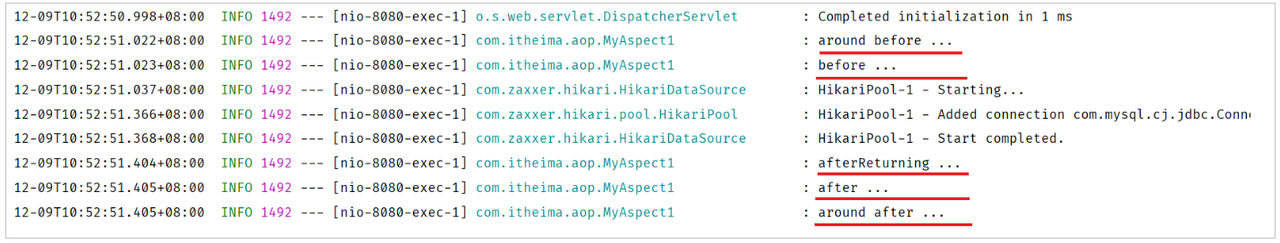

> 程序没有发生异常的情况下，@AfterThrowing标识的通知方法不会执行。

2). 出现异常情况下：

修改DeptServiceImpl业务实现类中的代码： 添加异常

```java
@Slf4j
@Service
public class DeptServiceImpl implements DeptService {
    @Autowired
    private DeptMapper deptMapper;

    @Override
    public List<Dept> list() {

        List<Dept> deptList = deptMapper.list();
        //模拟异常
        int num = 10/0;
        return deptList;
    }
    
    //省略其他代码...
}
```

重新启动SpringBoot服务，测试发生异常情况下通知的执行：

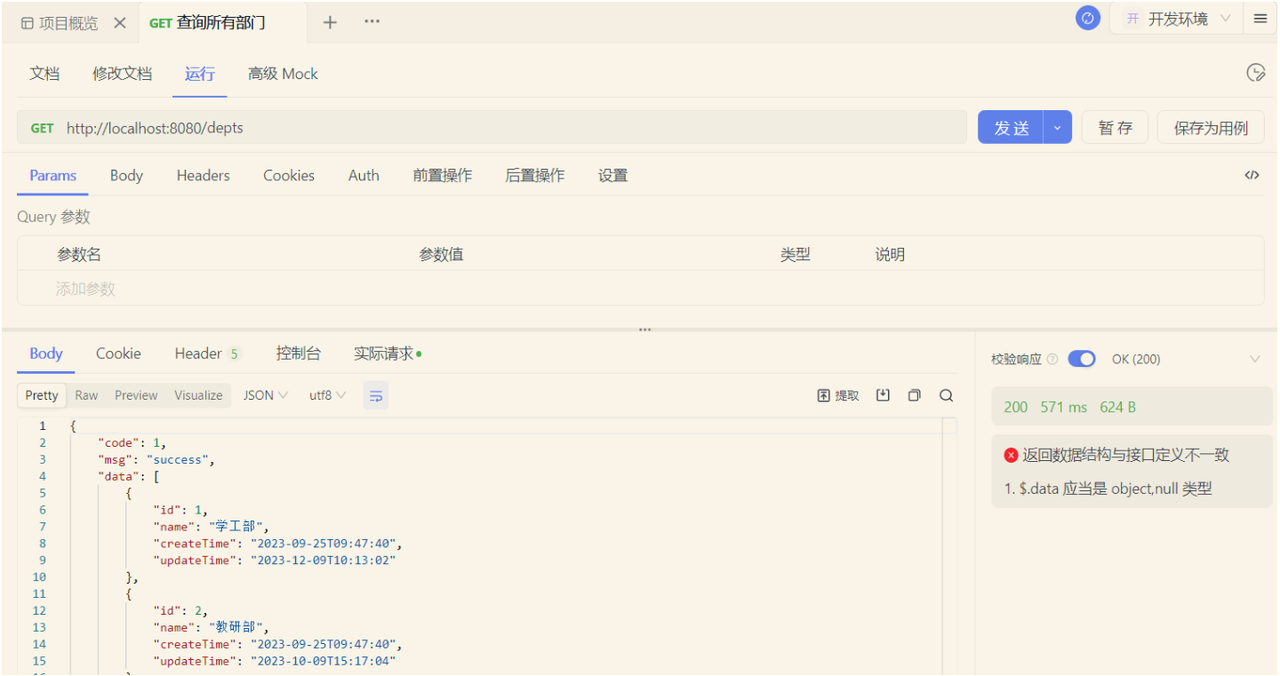

查看idea中控制台日志输出

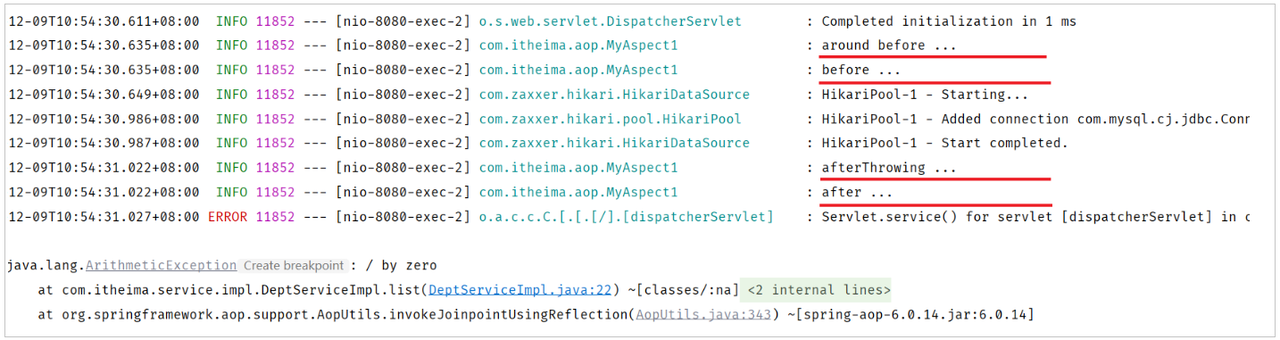

> 程序发生异常的情况下：

> - @AfterReturning标识的通知方法不会执行，@AfterThrowing标识的通知方法执行了

> - @Around环绕通知中原始方法调用时有异常，通知中的环绕后的代码逻辑也不会在执行了 （因为原始方法调用已经出异常了）

> **讲义提示**

> 在使用通知时的注意事项：

> - @Around环绕通知需要自己调用 ProceedingJoinPoint.proceed() 来让原始方法执行，其他通知不需要考虑目标方法执行

> - @Around环绕通知方法的返回值，必须指定为Object，来接收原始方法的返回值，否则原始方法执行完毕，是获取不到返回值的。

五种常见的通知类型，我们已经测试完毕了，此时我们再来看一下刚才所编写的代码，有什么问题吗？

```java
//前置通知
@Before("execution(* com.itheima.service.*.*(..))")

//环绕通知
@Around("execution(* com.itheima.service.*.*(..))")
  
//后置通知
@After("execution(* com.itheima.service.*.*(..))")

//返回后通知（程序在正常执行的情况下，会执行的后置通知）
@AfterReturning("execution(* com.itheima.service.*.*(..))")

//异常通知（程序在出现异常的情况下，执行的后置通知）
@AfterThrowing("execution(* com.itheima.service.*.*(..))")
```

我们发现啊，每一个注解里面都指定了切入点表达式，而且这些切入点表达式都一模一样。此时我们的代码当中就存在了大量的重复性的切入点表达式，假如此时切入点表达式需要变动，就需要将所有的切入点表达式一个一个的来改动，就变得非常繁琐了。

怎么来解决这个切入点表达式重复的问题？ 答案就是：抽取

Spring提供了@PointCut注解，该注解的作用是将公共的切入点表达式抽取出来，需要用到时引用该切入点表达式即可。

```java
@Slf4j
@Component
@Aspect
public class MyAspect1 {

    //切入点方法（公共的切入点表达式）
    @Pointcut("execution(* com.itheima.service.*.*(..))")
    private void pt(){}

    //前置通知（引用切入点）
    @Before("pt()")
    public void before(JoinPoint joinPoint){
        log.info("before ...");

    }

    //环绕通知
    @Around("pt()")
    public Object around(ProceedingJoinPoint proceedingJoinPoint) throws Throwable {
        log.info("around before ...");

        //调用目标对象的原始方法执行
        Object result = proceedingJoinPoint.proceed();
        //原始方法在执行时：发生异常
        //后续代码不在执行

        log.info("around after ...");
        return result;
    }

    //后置通知
    @After("pt()")
    public void after(JoinPoint joinPoint){
        log.info("after ...");
    }

    //返回后通知（程序在正常执行的情况下，会执行的后置通知）
    @AfterReturning("pt()")
    public void afterReturning(JoinPoint joinPoint){
        log.info("afterReturning ...");
    }

    //异常通知（程序在出现异常的情况下，执行的后置通知）
    @AfterThrowing("pt()")
    public void afterThrowing(JoinPoint joinPoint){
        log.info("afterThrowing ...");
    }
}
```

需要注意的是：当切入点方法使用private修饰时，仅能在当前切面类中引用该表达式， 当外部其他切面类中也要引用当前类中的切入点表达式，就需要把private改为public，而在引用的时候，具体的语法为：

```java
@Slf4j
@Component
@Aspect
public class MyAspect2 {
    //引用MyAspect1切面类中的切入点表达式
    @Before("com.itheima.aspect.MyAspect1.pt()")
    public void before(){
        log.info("MyAspect2 -> before ...");
    }
}
```

### 通知顺序

> **勘误｜默认顺序不是稳定契约。** 下方讲义示例观察到切面按类名字母排序执行，但 Spring 对未指定优先级的不同切面不保证这种顺序。需要稳定顺序时显式使用 `@Order` 或 `Ordered`：数值越小，优先级越高；进入调用链时先执行，退出调用链时后执行。相同优先级的切面也不要依赖类名决定顺序。

```text
@Order(1) 进入 -> @Order(2) 进入 -> 目标方法
@Order(1) 退出 <- @Order(2) 退出 <- 目标方法
```

讲解完了Spring中AOP所支持的5种通知类型之后，接下来我们再来研究通知的执行顺序。

当在项目开发当中，我们定义了多个切面类，而多个切面类中多个切入点都匹配到了同一个目标方法。此时当目标方法在运行的时候，这多个切面类当中的这些通知方法都会运行。

此时我们就有一个疑问，这多个通知方法到底哪个先运行，哪个后运行？ 下面我们通过程序来验证（这里呢，我们就定义两种类型的通知进行测试，一种是前置通知@Before，一种是后置通知@After）

定义多个切面类：

```java
@Slf4j
@Component
@Aspect
public class MyAspect2 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect2 -> before ...");
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect2 -> after ...");
    }
}
```

```java
@Slf4j
@Component
@Aspect
public class MyAspect3 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect3 -> before ...");
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect3 ->  after ...");
    }
}
```

```java
@Slf4j
@Component
@Aspect
public class MyAspect4 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect4 -> before ...");
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect4 -> after ...");
    }
}
```

重新启动SpringBoot服务，测试通知的执行顺序：

> 备注：

> 1. 把DeptServiceImpl实现类中模拟异常的代码删除或注释掉。

> 1. 注释掉其他切面类(把@Aspect注释即可)，仅保留MyAspect2、MyAspect3、MyAspect4 ，这样就可以清晰看到执行的结果，而不被其他切面类干扰。

使用 Apifox 测试查询所有部门数据。

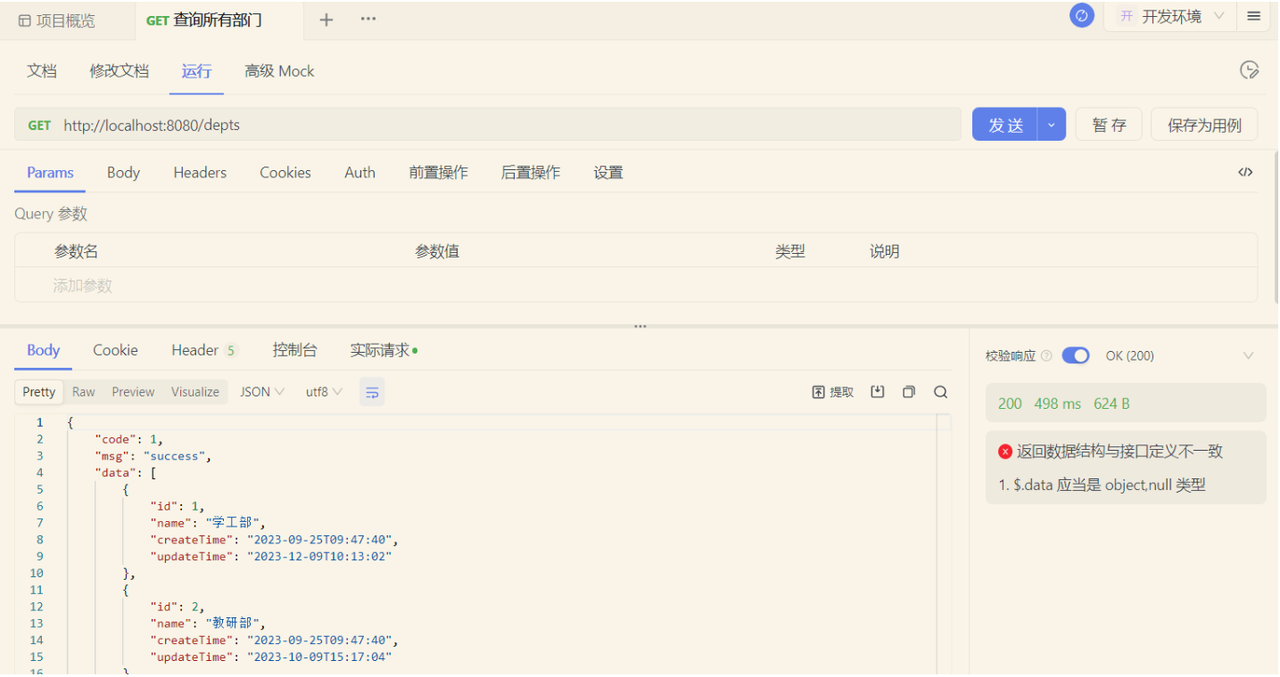

查看idea中控制台日志输出

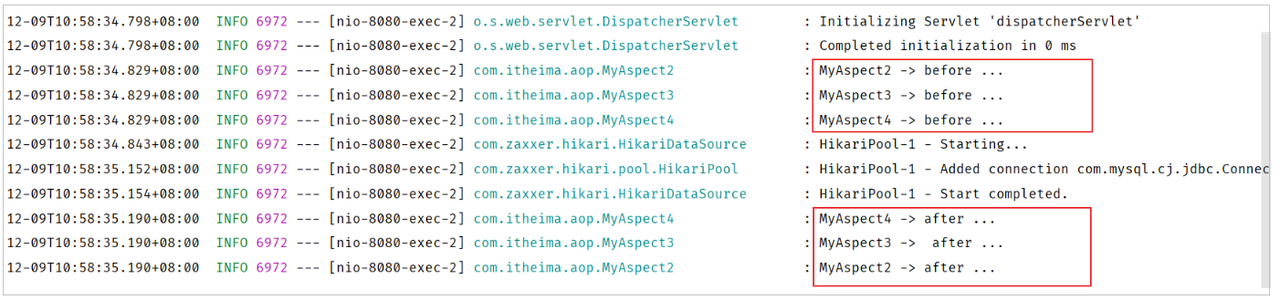

- 通过以上程序运行可以看出在不同切面类中，默认按照切面类的类名字母排序：

    - 目标方法前的通知方法：字母排名靠前的先执行

    - 目标方法后的通知方法：字母排名靠前的后执行

如果我们想控制通知的执行顺序有两种方式：

1. 修改切面类的类名（这种方式非常繁琐、而且不便管理）

1. 使用Spring提供的@Order注解

使用@Order注解，控制通知的执行顺序：

```java
@Slf4j
@Component
@Aspect
@Order(2)  //切面类的执行顺序（前置通知：数字越小先执行; 后置通知：数字越小越后执行）
public class MyAspect2 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect2 -> before ...");
    }

    //后置通知 
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect2 -> after ...");
    }
}
```

```java
@Slf4j
@Component
@Aspect
@Order(3)  //切面类的执行顺序（前置通知：数字越小先执行; 后置通知：数字越小越后执行）
public class MyAspect3 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect3 -> before ...");
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect3 ->  after ...");
    }
}
```

```java
@Slf4j
@Component
@Aspect
@Order(1) //切面类的执行顺序（前置通知：数字越小先执行; 后置通知：数字越小越后执行）
public class MyAspect4 {
    //前置通知
    @Before("execution(* com.itheima.service.*.*(..))")
    public void before(){
        log.info("MyAspect4 -> before ...");
    }

    //后置通知
    @After("execution(* com.itheima.service.*.*(..))")
    public void after(){
        log.info("MyAspect4 -> after ...");
    }
}
```

重新启动SpringBoot服务，测试通知执行顺序：

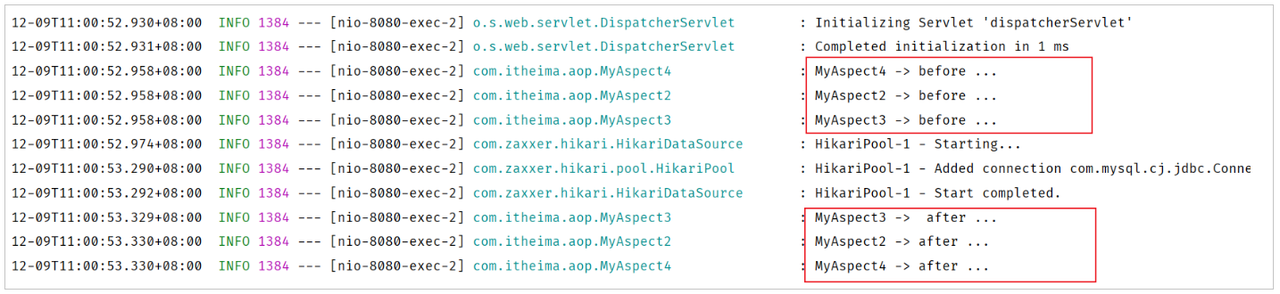

> **讲义提示**

> 通知的执行顺序大家主要知道两点即可：

> 1. 不同的切面类当中，默认情况下通知的执行顺序是与切面类的类名字母排序是有关系的

> 1. 可以在切面类上面加上@Order注解，来控制不同的切面类通知的执行顺序

### 切入点表达式

从AOP的入门程序到现在，我们一直都在使用切入点表达式来描述切入点。下面我们就来详细的介绍一下切入点表达式的具体写法。

切入点表达式：描述切入点方法的一种表达式

- 作用：主要用来决定项目中的哪些方法需要加入通知

- 常见形式：

    - execution(……)：根据方法的签名来匹配

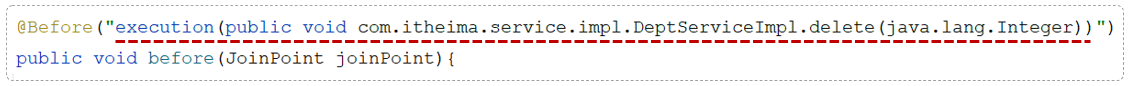

    - @annotation(……) ：根据注解匹配

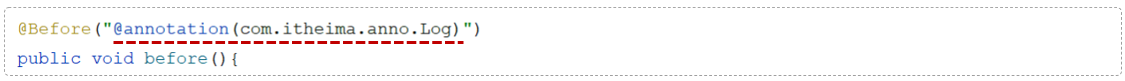

首先我们先学习第一种最为常见的execution切入点表达式。

#### execution

> **补充｜表达式与 Java 代码的区别。** `execution(...)` 是 AspectJ 切入点表达式，写在通知注解的字符串中；讲义中的独立表达式用于说明匹配规则。参数位置的 `*` 表示恰好一个任意类型参数，`..` 表示零个或多个参数；包路径中的 `*` 匹配一层，`..` 匹配零层或多层。`()` 表示无参方法，`(*)` 不匹配无参方法。签名参数 `int` 与 `java.lang.Integer` 应按实际声明书写。

execution主要根据方法的返回值、包名、类名、方法名、方法参数等信息来匹配，语法为：

```java
execution(访问修饰符?  返回值  包名.类名.?方法名(方法参数) throws 异常?)
```

其中带?的表示可以省略的部分

- 访问修饰符：可省略（比如: public、protected）

- 包名.类名： 可省略

- throws 异常：可省略（注意是方法上声明抛出的异常，不是实际抛出的异常）

示例：

```java
@Before("execution(void com.itheima.service.impl.DeptServiceImpl.delete(java.lang.Integer))")
```

可以使用通配符描述切入点

- \* ：单个独立的任意符号，可以通配任意返回值、包名、类名、方法名、任意类型的一个参数，也可以通配包、类、方法名的一部分

- .. ：多个连续的任意符号，可以通配任意层级的包，或任意类型、任意个数的参数

切入点表达式的语法规则：

1. 方法的访问修饰符可以省略

1. 返回值可以使用\*号代替（任意返回值类型）

1. 包名可以使用\*号代替，代表任意包（一层包使用一个\*）

1. 使用..配置包名，标识此包以及此包下的所有子包

1. 类名可以使用\*号代替，标识任意类

1. 方法名可以使用\*号代替，表示任意方法

1. 可以使用 \*  配置参数，一个任意类型的参数

1. 可以使用.. 配置参数，任意个任意类型的参数

切入点表达式示例

- 省略方法的修饰符号

```java
execution(void com.itheima.service.impl.DeptServiceImpl.delete(java.lang.Integer))
```

- 使用\*代替返回值类型

```java
execution(* com.itheima.service.impl.DeptServiceImpl.delete(java.lang.Integer))
```

- 使用\*代替包名（一层包使用一个\*）

```java
execution(* com.itheima.*.*.DeptServiceImpl.delete(java.lang.Integer))
```

- 使用..省略包名

```java
execution(* com..DeptServiceImpl.delete(java.lang.Integer))  
```

- 使用\*代替类名

```java
execution(* com..*.delete(java.lang.Integer))
```

- 使用\*代替方法名

```java
execution(* com..*.*(java.lang.Integer))
```

- 使用 \* 代替参数

```java
execution(* com.itheima.service.impl.DeptServiceImpl.delete(*))
```

- 使用..省略参数

```java
execution(* com..*.*(..))
```

注意事项：

- 根据业务需要，可以使用 且（&&）、或（||）、非（!） 来组合比较复杂的切入点表达式。

```java
execution(* com.itheima.service.DeptService.list(..)) || execution(* com.itheima.service.DeptService.delete(..))
```

切入点表达式的书写建议：

- 所有业务方法名在命名时尽量规范，方便切入点表达式快速匹配。如：查询类方法都是 find 开头，更新类方法都是update开头

```java
//业务类
@Service
public class DeptServiceImpl implements DeptService {
    
    public List<Dept> findAllDept() {
       //省略代码...
    }
    
    public Dept findDeptById(Integer id) {
       //省略代码...
    }
    
    public void updateDeptById(Integer id) {
       //省略代码...
    }
    
    public void updateDeptByMoreCondition(Dept dept) {
       //省略代码...
    }
    //其他代码...
}
```

- //匹配DeptServiceImpl类中以find开头的方法

```java
execution(* com.itheima.service.impl.DeptServiceImpl.find*(..))
```

- 描述切入点方法通常基于接口描述，而不是直接描述实现类，增强拓展性

```java
execution(* com.itheima.service.DeptService.*(..))
```

- 在满足业务需要的前提下，尽量缩小切入点的匹配范围。如：包名匹配尽量不使用 ..，使用 \* 匹配单个包

```java
execution(* com.itheima.*.*.DeptServiceImpl.find*(..))
```

> 切入点表达式书写建议：

> - 所有业务方法名在命名时尽量规范，方便切入点表达式快速匹配。如：findXxx，updateXxx。

> - 描述切入点方法通常基于接口描述，而不是直接描述实现类，增强拓展性。

> - 在满足业务需要的前提下，尽量缩小切入点的匹配范围。如：包名尽量不使用..，使用 \* 匹配单个包。

#### @annotation

> **补充｜运行时注解与绑定。** `@LogOperation` 需使用 `@Target(ElementType.METHOD)` 和 `@Retention(RetentionPolicy.RUNTIME)`。`@annotation(com.itheima.anno.LogOperation)` 通过类型匹配；`@annotation(log)` 把注解对象绑定到通知方法的 `LogOperation log` 参数。若参数名无法自动发现，可在 `@Around` 中显式指定 `argNames = "joinPoint,log"`。本课程可把标记放在实际执行的实现类或 Controller 方法上，并验证代理调用能匹配到它。

已经学习了execution切入点表达式的语法。那么如果我们要匹配多个无规则的方法，比如：list()和 delete()这两个方法。这个时候我们基于execution这种切入点表达式来描述就不是很方便了。而在之前我们是将两个切入点表达式组合在了一起完成的需求，这个是比较繁琐的。

我们可以借助于另一种切入点表达式 @annotation 来描述这一类的切入点，从而来简化切入点表达式的书写。

实现步骤：

1. 编写自定义注解

1. 在业务类要做为连接点的方法上添加自定义注解

自定义注解：LogOperation

```java
@Target(ElementType.METHOD)
@Retention(RetentionPolicy.RUNTIME)
public @interface LogOperation{
}
```

业务类：DeptServiceImpl

```java
@Slf4j
@Service
public class DeptServiceImpl implements DeptService {
    @Autowired
    private DeptMapper deptMapper;

    @Override
    @LogOperation //自定义注解（表示：当前方法属于目标方法）
    public List<Dept> list() {
        List<Dept> deptList = deptMapper.list();
        //模拟异常
        //int num = 10/0;
        return deptList;
    }

    @Override
    @LogOperation //自定义注解（表示：当前方法属于目标方法）
    public void delete(Integer id) {
        //1. 删除部门
        deptMapper.delete(id);
    }


    @Override
    public void save(Dept dept) {
        dept.setCreateTime(LocalDateTime.now());
        dept.setUpdateTime(LocalDateTime.now());
        deptMapper.save(dept);
    }

    @Override
    public Dept getById(Integer id) {
        return deptMapper.getById(id);
    }

    @Override
    public void update(Dept dept) {
        dept.setUpdateTime(LocalDateTime.now());
        deptMapper.update(dept);
    }
}
```

切面类

```java
@Slf4j
@Component
@Aspect
public class MyAspect6 {
    //针对list方法、delete方法进行前置通知和后置通知

    //前置通知
    @Before("@annotation(com.itheima.anno.LogOperation)")
    public void before(){
        log.info("MyAspect6 -> before ...");
    }
    
    //后置通知
    @After("@annotation(com.itheima.anno.LogOperation)")
    public void after(){
        log.info("MyAspect6 -> after ...");
    }
}
```

重启SpringBoot服务，测试查询所有部门数据，查看控制台日志：

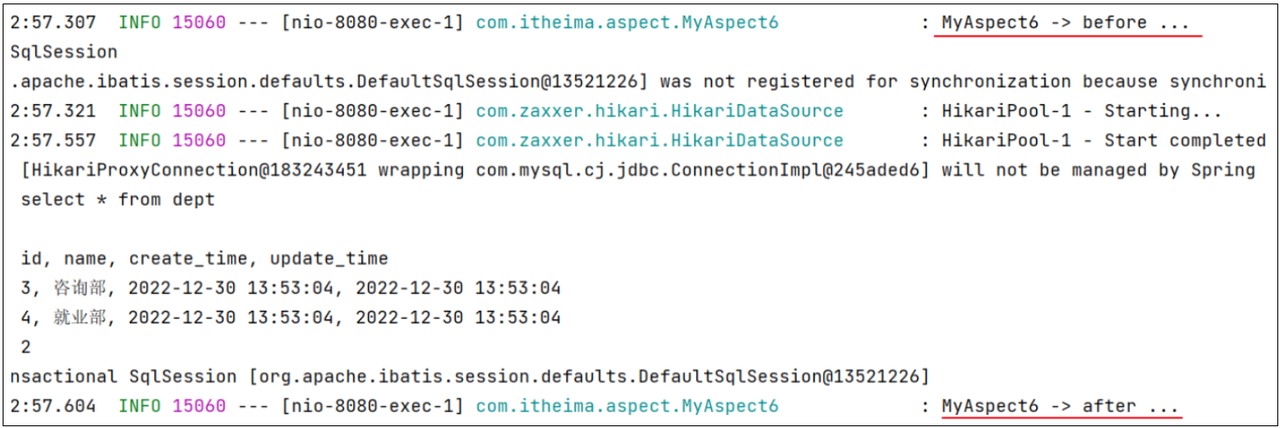

到此我们两种常见的切入点表达式我已经介绍完了。

- execution切入点表达式

    - 根据我们所指定的方法的描述信息来匹配切入点方法，这种方式也是最为常用的一种方式

    - 如果我们要匹配的切入点方法的方法名不规则，或者有一些比较特殊的需求，通过execution切入点表达式描述比较繁琐

- annotation 切入点表达式

    - 基于注解的方式来匹配切入点方法。这种方式虽然多一步操作，我们需要自定义一个注解，但是相对来比较灵活。我们需要匹配哪个方法，就在方法上加上对应的注解就可以了

> **讲义提示**

> 根据业务需要，可以使用 && ，||，！ 来组合比较复杂的切入点表达式。

## AOP案例

SpringAOP的相关知识我们就已经全部学习完毕了。最后我们要通过一个案例来对AOP进行一个综合的应用。

### 需求

需求：将案例（Tlias智能学习辅助系统）中增、删、改相关接口的操作日志记录到数据库表中

- 就是当访问部门管理和员工管理当中的增、删、改相关功能接口时，需要详细的操作日志，并保存在数据表中，便于后期数据追踪。

操作日志信息包含：

- 操作人、操作时间、执行方法的全类名、执行方法名、方法运行时参数、返回值、方法执行时长

> 所记录的日志信息包括当前接口的操作人是谁操作的，什么时间点操作的，以及访问的是哪个类当中的哪个方法，在访问这个方法的时候传入进来的参数是什么，访问这个方法最终拿到的返回值是什么，以及整个接口方法的运行时长是多长时间。

### 分析

- 问题1：项目当中增删改相关的方法是不是有很多？

    - 很多

- 问题2：我们需要针对每一个功能接口方法进行修改，在每一个功能接口当中都来记录这些操作日志吗？

    - 这种做法比较繁琐

以上两个问题的解决方案：可以使用AOP解决(每一个增删改功能接口中要实现的记录操作日志的逻辑代码是相同)。

可以把这部分记录操作日志的通用的、重复性的逻辑代码抽取出来定义在一个通知方法当中，我们通过AOP面向切面编程的方式，在不改动原始功能的基础上来对原始的功能进行增强。目前我们所增强的功能就是来记录操作日志，所以也可以使用AOP的技术来实现。使用AOP的技术来实现也是最为简单，最为方便的。

- 问题3：既然要基于AOP面向切面编程的方式来完成的功能，那么我们要使用 AOP五种通知类型当中的哪种通知类型？

    - 答案：环绕通知 @Around。因为所记录的操作日志当中包括：操作人、操作时间，访问的是哪个类、哪个方法、方法运行时参数、方法的返回值、方法的运行时长。方法返回值，是在原始方法执行后才能获取到的。方法的运行时长，需要原始方法运行之前记录开始时间，原始方法运行之后记录结束时间。通过计算获得方法的执行耗时。基于以上的分析我们确定要使用Around环绕通知。

- 问题4：最后一个问题，切入点表达式我们该怎么写？

    - 答案：使用 @annotation 来描述切入点表达式。要匹配业务接口当中所有的增删改的方法，而增删改方法在命名上没有共同的前缀或后缀。此时如果使用execution切入点表达式也可以，但是会比较繁琐。 当遇到增删改的方法名没有规律时，就可以使用 @annotation切入点表达式

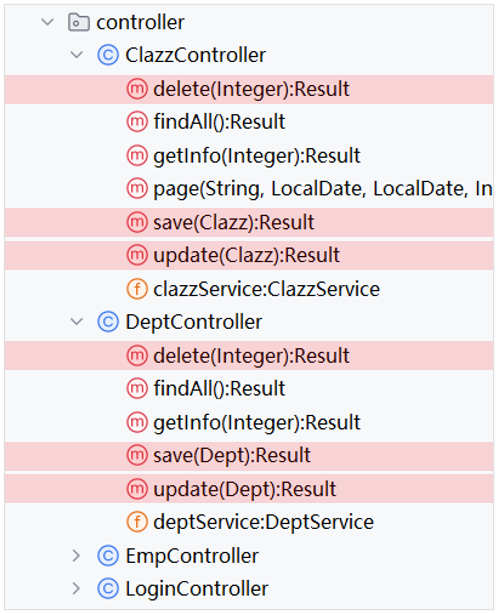

### 步骤

简单分析了一下大概的实现思路后，接下来我们就要来完成案例了。案例的实现步骤其实就两步：

- 准备工作

    1. 引入AOP的起步依赖

    1. 导入资料中准备好的数据库表结构，并引入对应的实体类

- 编码实现(基于AI实现)

    1. 自定义注解@LogOperation

    1. 定义切面类，完成记录操作日志的逻辑

### 代码实现

> **补充｜操作日志案例的实现范围。** 下方保留讲义的 AI 提示词、建表语句和原始实现。第一版 `getCurrentUserId()` 固定返回 `1` 是占位逻辑，后面将接入第 12 章的 JWT 和 `CurrentHolder`。原始切面只会在正常返回后写入日志，记录的“成功”是 Controller 方法正常返回，不能据此保证事务已经提交；若要记录失败或提交后的审计信息，需要定义相应状态与事务时机。

> **讲义提示**

> 请帮我基于Spring AOP中的环绕通知 @Around 实现记录系统所有增、删、改功能接口的操作日志。具体信息如下：

> 1. 日志信息包含：操作人、操作时间、执行方法的全类名、执行方法名、方法运行时参数、返回值、方法执行时长

> 1. 功能接口所在包为 com.itheima.controller

> 1. 日志表为 operate_log 表，对应的实体类为 OperateLog。 具体表结构如下：

> create table operate_log(

> id int unsigned primary key auto_increment comment 'ID',

> operate_emp_id int unsigned comment '操作人ID',

> operate_time datetime comment '操作时间',

> class_name varchar(100) comment '操作的类名',

> method_name varchar(100) comment '操作的方法名',

> method_params varchar(1000) comment '方法参数',

> return_value varchar(2000) comment '返回值',

> cost_time int comment '方法执行耗时, 单位:ms'

> ) comment '操作日志表';

> 1. 并且已经提供了OperateLogMapper接口来操作 operate_log, 并在其中已经定义好了 insert 方法用来保存日志数据.

1). 准备工作

- 在 pom.xml 中引入AOP的依赖

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-aop</artifactId>
</dependency>
```

- 创建数据库表结构

```sql
-- 操作日志表
create table operate_log(
    id int unsigned primary key auto_increment comment 'ID',
    operate_emp_id int unsigned comment '操作人ID',
    operate_time datetime comment '操作时间',
    class_name varchar(100) comment '操作的类名',
    method_name varchar(100) comment '操作的方法名',
    method_params varchar(1000) comment '方法参数',
    return_value varchar(2000) comment '返回值, 存储json格式',
    cost_time int comment '方法执行耗时, 单位:ms'
) comment '操作日志表';
```

- 引入资料中准备的实体类

```java
package com.itheima.pojo;

import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.time.LocalDateTime;

@Data
@NoArgsConstructor
@AllArgsConstructor
public class OperateLog {
    private Integer id; //ID
    private Integer operateEmpId; //操作人ID
    private LocalDateTime operateTime; //操作时间
    private String className; //操作类名
    private String methodName; //操作方法名
    private String methodParams; //操作方法参数
    private String returnValue; //操作方法返回值
    private Long costTime; //操作耗时
}
```

- 引入资料中准备的日志操作Mapper接口 OperateLogMapper

```java
package com.itheima.mapper;

import com.itheima.pojo.OperateLog;
import org.apache.ibatis.annotations.Insert;
import org.apache.ibatis.annotations.Mapper;

@Mapper
public interface OperateLogMapper {
    
    //插入日志数据
    @Insert("insert into operate_log (operate_emp_id, operate_time, class_name, method_name, method_params, return_value, cost_time) " +
            "values (#{operateEmpId}, #{operateTime}, #{className}, #{methodName}, #{methodParams}, #{returnValue}, #{costTime});")
    public void insert(OperateLog log);
    
}
```

1). 自定义注解 @LogOperation

```java
/**
 *  自定义注解，用于标识哪些方法需要记录日志
 */
@Target(ElementType.METHOD)
@Retention(RetentionPolicy.RUNTIME)
public @interface LogOperation {
}
```

2). 定义AOP记录日志的切面类

```java
import com.itheima.anno.LogOperation;
import com.itheima.mapper.OperateLogMapper;
import com.itheima.pojo.OperateLog;
import org.aspectj.lang.ProceedingJoinPoint;
import org.aspectj.lang.annotation.Around;
import org.aspectj.lang.annotation.Aspect;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Component;
import java.time.LocalDateTime;
import java.util.Arrays;

@Aspect
@Component
public class OperationLogAspect {

    @Autowired
    private OperateLogMapper operateLogMapper;

    // 环绕通知
    @Around("@annotation(log)")
    public Object around(ProceedingJoinPoint joinPoint, LogOperation log) throws Throwable {
        // 记录开始时间
        long startTime = System.currentTimeMillis();
        // 执行方法
        Object result = joinPoint.proceed();
        // 当前时间
        long endTime = System.currentTimeMillis();
        // 耗时
        long costTime = endTime - startTime;

        // 构建日志对象
        OperateLog operateLog = new OperateLog();
        operateLog.setOperateEmpId(getCurrentUserId()); // 需要实现 getCurrentUserId 方法
        operateLog.setOperateTime(LocalDateTime.now());
        operateLog.setClassName(joinPoint.getTarget().getClass().getName());
        operateLog.setMethodName(joinPoint.getSignature().getName());
        operateLog.setMethodParams(Arrays.toString(joinPoint.getArgs()));
        operateLog.setReturnValue(result.toString());
        operateLog.setCostTime(costTime);

        // 插入日志
        operateLogMapper.insert(operateLog);
        return result;
    }
    
    // 示例方法，获取当前用户ID
    private int getCurrentUserId() {
        // 这里应该根据实际情况从认证信息中获取当前登录用户的ID
        return 1; // 示例返回值
    }
}
```

> **实现补充｜参数与返回值。** `Arrays.toString()` 和 `result.toString()` 不是可靠的 JSON 序列化，后者还可能因返回值为 `null` 抛异常。若字段约定保存 JSON，使用项目的 `ObjectMapper`；参数与返回值按需脱敏并限制长度，文件、流、Request/Response 等对象不要直接全量序列化。`method_params` 和 `return_value` 分别只有 1000、2000 字符，应明确截断策略或调整字段类型。日志写入失败是否影响业务应按需求确定，不能在业务已经完成后返回失败却没有相应处理策略。

3). 在需要记录的日志的Controller层的方法上，加上注解 @LogOperation

```java
@RestController
@RequestMapping("/clazzs")
public class ClazzController {

    @Autowired
    private ClazzService clazzService;

    /**
     * 新增班级
     */
    @LogOperation
    @PostMapping
    public Result save(@RequestBody Clazz clazz){
        clazzService.save(clazz);
        return Result.success();
    }
}    
```

重启SpringBoot服务，测试操作日志记录功能：

打开浏览器，针对于员工的数据、部门的数据进行增删改之后。我们打开数据库表结构可以来看一下：

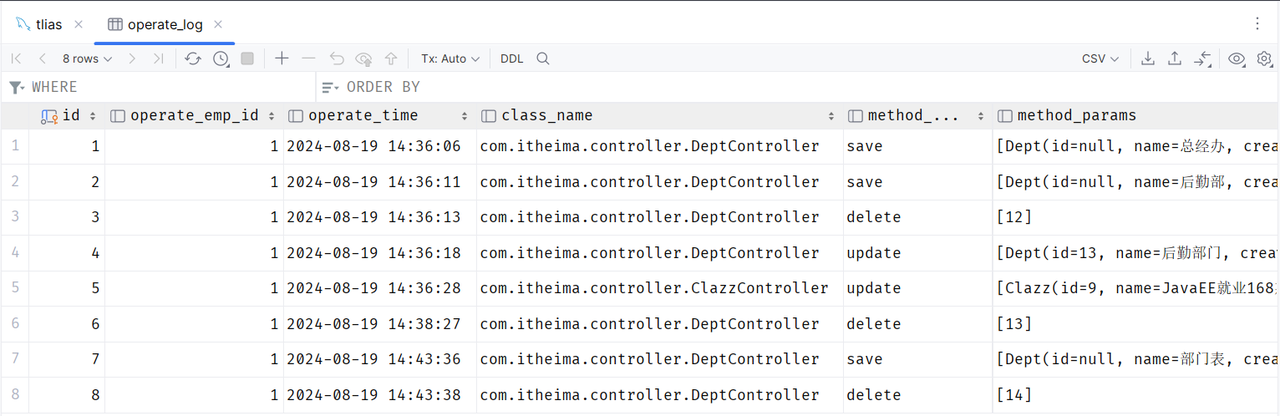

我们会看到，在数据库表中，就清晰的记录了谁、什么时间点、调用了哪个类的哪个方法、传入了什么参数、返回了什么数据，都清晰的记录在数据库中了。

### 连接点

> **补充｜读取调用现场。** `JoinPoint` 可读取目标对象、方法签名和实参；`ProceedingJoinPoint` 继承它，并提供 `proceed()`。环绕通知需要主动执行目标调用时使用 `ProceedingJoinPoint`；若只读取信息，`JoinPoint` 也可用于环绕通知，但没有 `proceed()` 方法。其他四种通知使用 `JoinPoint`，目标方法的执行由框架控制。

| 需要的信息 | 常用 API | 示例用途 |
| --- | --- | --- |
| 目标对象 | `getTarget()` | 获取业务类名 |
| 方法签名 | `getSignature()` | 获取方法名和声明信息 |
| 方法参数 | `getArgs()` | 获取调用时的参数数组 |
| 代理对象 | `getThis()` | 区分 Spring 代理与实际目标 |
| 执行目标方法 | `ProceedingJoinPoint.proceed()` | 获取返回值、统计耗时 |

我们前面在讲解AOP核心概念的时候，我们提到过什么是连接点，连接点可以简单理解为可以被AOP控制的方法。

我们目标对象当中所有的方法是不是都是可以被AOP控制的方法。而在SpringAOP当中，连接点又特指方法的执行。

在Spring中用JoinPoint抽象了连接点，用它可以获得方法执行时的相关信息，如目标类名、方法名、方法参数等。

- 对于@Around通知，获取连接点信息只能使用ProceedingJoinPoint类型

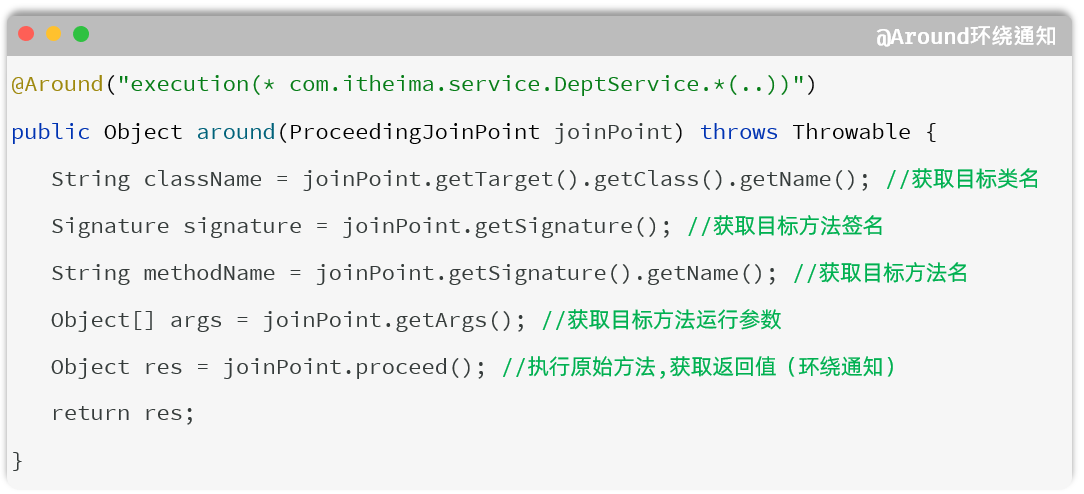

- 对于其他四种通知，获取连接点信息只能使用JoinPoint，它是ProceedingJoinPoint的父类型

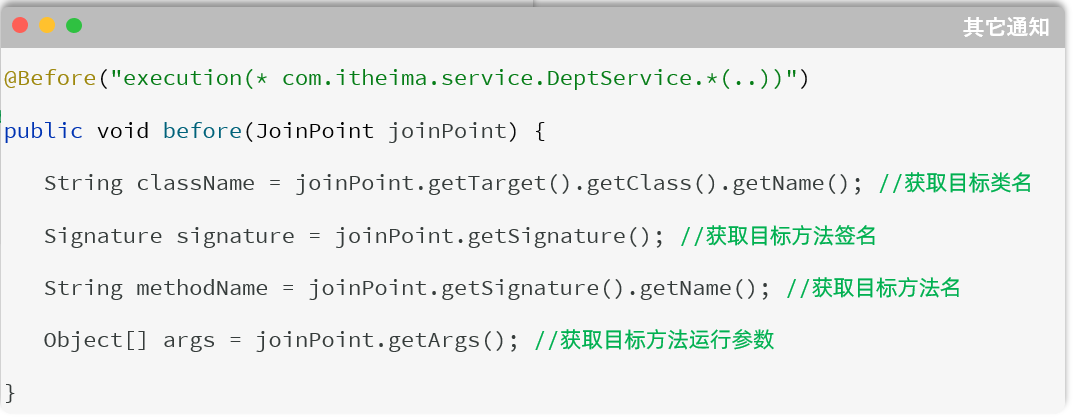

### 获取当前登录员工

- 员工登录成功后，哪里存储的有当前登录员工的信息？ 给客户端浏览器下发的jwt令牌中

- 如何从JWT令牌中获取当前登录用户的信息呢？ 获取请求头中传递的jwt令牌，并解析

- TokenFilter 中已经解析了令牌的信息，如何传递给AOP程序、Controller、Service呢？ThreadLocal

#### ThreadLocal

> **补充｜线程与请求不是同一概念。** 在本章同步 Servlet 请求中，Filter、Controller、Service 和切面通常运行在同一线程，因而可以共享员工 ID。`ThreadLocal` 的隔离单位是线程，不是请求；线程池会复用线程，所以请求结束必须清理。异步任务、`@Async` 或响应式链路不会自动继承这份上下文，应显式传递身份信息或使用对应的上下文机制。

- ThreadLocal 并不是一个Thread，而是Thread的局部变量。

- ThreadLocal为每个线程提供一份单独的存储空间，具有线程隔离的效果，不同的线程之间不会相互干扰。

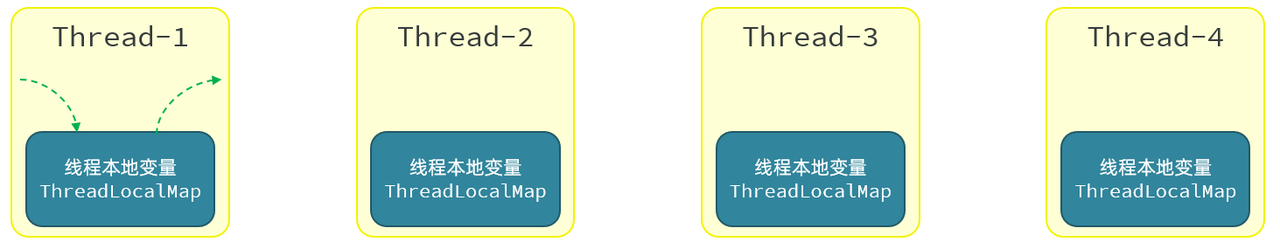

- 常见方法：

    - public void set(T value)   设置当前线程的线程局部变量的值

    - public T get()                     返回当前线程所对应的线程局部变量的值

    - public void remove()          移除当前线程的线程局部变量

#### 记录当前登录员工

> **勘误｜清理要覆盖异常。** 讲义在 `filterChain.doFilter()` 之后调用 `CurrentHolder.remove()`；若下游抛异常，清理可能被跳过。应使用 `try/finally` 包住整个请求处理，并在 `finally` 中清理。员工 ID 必须来自已验签、已校验过期时间的 JWT，不能直接信任请求参数中的 ID。沿用第 12 章的准确放行路径，避免以 `uri.contains("login")` 作为认证豁免条件。

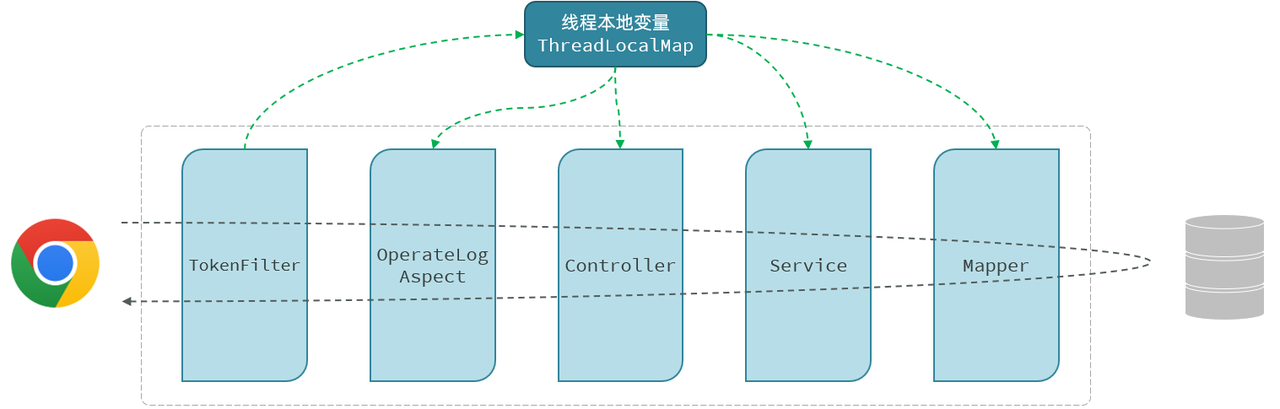

具体操作步骤：

1. 定义ThreadLocal操作的工具类，用于操作当前登录员工ID。

在 com.itheima.utils 引入工具类 CurrentHolder

```java
package com.itheima.utils;

public class CurrentHolder {

    private static final ThreadLocal<Integer> CURRENT_LOCAL = new ThreadLocal<>();

    public static void setCurrentId(Integer employeeId) {
        CURRENT_LOCAL.set(employeeId);
    }

    public static Integer getCurrentId() {
        return CURRENT_LOCAL.get();
    }

    public static void remove() {
        CURRENT_LOCAL.remove();
    }
}
```

1. 在TokenFilter中，解析完当前登录员工ID，将其存入ThreadLocal（用完之后需将其删除）。

```java
package com.itheima.filter;

import com.itheima.utils.CurrentHolder;
import com.itheima.utils.JwtUtils;
import io.jsonwebtoken.Claims;
import jakarta.servlet.*;
import jakarta.servlet.annotation.WebFilter;
import jakarta.servlet.http.HttpServletRequest;
import jakarta.servlet.http.HttpServletResponse;
import lombok.extern.slf4j.Slf4j;
import java.io.IOException;

@Slf4j
@WebFilter(urlPatterns = "/*")
public class TokenFilter implements Filter {
    @Override
    public void doFilter(ServletRequest servletRequest, ServletResponse servletResponse, FilterChain filterChain) throws IOException, ServletException {
        HttpServletRequest request = (HttpServletRequest) servletRequest;
        HttpServletResponse response = (HttpServletResponse) servletResponse;

        //1. 获取请求的url地址
        String uri = request.getRequestURI(); // /employee/login
        //String url = request.getRequestURL().toString(); // http://localhost:8080/employee/login

        //2. 判断是否是登录请求, 如果url地址中包含 login, 则说明是登录请求, 放行
        if (uri.contains("login")) {
            log.info("登录请求, 放行");
            filterChain.doFilter(request, response);
            return;
        }

        //3. 获取请求中的token
        String token = request.getHeader("token");

        //4. 判断token是否为空, 如果为空, 响应401状态码
        if (token == null || token.isEmpty()) {
            log.info("token为空, 响应401状态码");
            response.setStatus(401); // 响应401状态码
            return;
        }

        //5. 如果token不为空, 调用JWtUtils工具类的方法解析token, 如果解析失败, 响应401状态码
        try {
            Claims claims = JwtUtils.parseJWT(token);
            Integer empId = Integer.valueOf(claims.get("id").toString());
            CurrentHolder.setCurrentId(empId);
            log.info("token解析成功, 放行");
        } catch (Exception e) {
            log.info("token解析失败, 响应401状态码");
            response.setStatus(401);
            return;
        }

        //6. 放行
        filterChain.doFilter(request, response);

        //7. 清空当前线程绑定的id
        CurrentHolder.remove();
    }
}
```

1. 在AOP程序中，从ThreadLocal中获取当前登录员工的ID。

```java
package com.itheima.aop;

import com.itheima.anno.LogOperation;
import com.itheima.mapper.OperateLogMapper;
import com.itheima.pojo.OperateLog;
import com.itheima.utils.CurrentHolder;
import org.aspectj.lang.ProceedingJoinPoint;
import org.aspectj.lang.annotation.Around;
import org.aspectj.lang.annotation.Aspect;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Component;

import java.time.LocalDateTime;
import java.util.Arrays;

@Aspect
@Component
public class OperationLogAspect {

    @Autowired
    private OperateLogMapper operateLogMapper;

    // 环绕通知
    @Around("@annotation(log)")
    public Object around(ProceedingJoinPoint joinPoint, LogOperation log) throws Throwable {
        // 记录开始时间
        long startTime = System.currentTimeMillis();
        // 执行方法
        Object result = joinPoint.proceed();
        // 当前时间
        long endTime = System.currentTimeMillis();
        // 耗时
        long costTime = endTime - startTime;

        // 构建日志对象
        OperateLog operateLog = new OperateLog();
        operateLog.setOperateEmpId(getCurrentUserId()); // 需要实现 getCurrentUserId 方法
        operateLog.setOperateTime(LocalDateTime.now());
        operateLog.setClassName(joinPoint.getTarget().getClass().getName());
        operateLog.setMethodName(joinPoint.getSignature().getName());
        operateLog.setMethodParams(Arrays.toString(joinPoint.getArgs()));
        operateLog.setReturnValue(result.toString());
        operateLog.setCostTime(costTime);

        // 插入日志
        operateLogMapper.insert(operateLog);
        return result;
    }

    // 示例方法，获取当前用户ID
    private int getCurrentUserId() {
        return CurrentHolder.getCurrentId();
    }
}
```

> **勘误｜空身份值。** 原示例的 `getCurrentUserId()` 返回 `int`，而 `CurrentHolder.getCurrentId()` 返回 `Integer`。上下文缺失时自动拆箱会抛 `NullPointerException`；应显式拒绝缺失身份，或按需求以 `Integer` 表示系统操作。记录操作人前应验证当前请求已经通过认证。

代码优化完毕之后，我们重新启动服务测试。就可以看到，可以获取到不同的登录用户信息了。

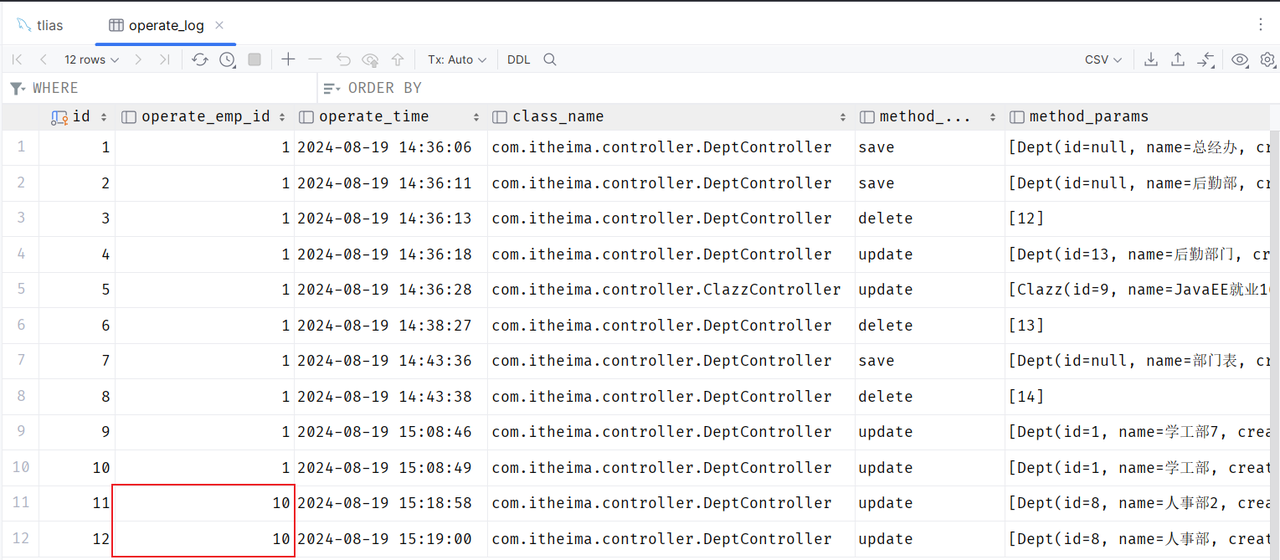

> **讲义提示**

> 在同一个线程/同一个请求中，进行数据共享就可以使用 ThreadLocal。

## 复习速查与跟练验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 切面注册 | `@Aspect` 声明切面，`@Component` 注册 Bean | 只有 `@Aspect` 却未让 Spring 管理对象 |
| `@Before` | 目标方法之前执行 | 用它获取尚未产生的返回值 |
| `@After` | 正常、异常退出时都会执行 | 当成“仅正常返回后”通知 |
| `@AfterReturning` | 目标方法正常返回后执行 | 以为它能直接替换调用方收到的返回值 |
| `@AfterThrowing` | 匹配抛出的异常 | 以为它会自动吞掉异常 |
| `@Around` | 主动控制 `proceed()`、返回值与异常 | 忘记执行目标方法或忘记返回结果 |
| `@Pointcut` | 抽取表达式，通过方法名引用 | 跨类引用 `private` 的切入点方法 |
| `@Order` | 数值越小优先级越高，进入先执行、退出后执行 | 依赖未排序切面的类名字母顺序 |
| `execution` | 按方法签名匹配，区分 `*`、`..` 与 `()` | 切入点太宽，误拦截不相关 Bean |
| `@annotation` | 按方法上的运行时注解匹配 | 注解缺少 `RetentionPolicy.RUNTIME` |
| `ThreadLocal` | 同一线程共享，结束后 `remove()` | 以为线程池每次请求都分配全新线程 |

### 同时覆盖成功和异常的计时写法（补充）

以下片段可替换入门示例的通知方法，继续保留切面类上的 `@Aspect`、`@Component`、`@Slf4j`。

```java
@Around("execution(* com.itheima.service.impl.DeptServiceImpl.*(..))")
public Object recordTime(ProceedingJoinPoint pjp) throws Throwable {
    long begin = System.nanoTime();
    try {
        return pjp.proceed();
    } finally {
        long elapsed = System.nanoTime() - begin;
        log.info("{} 耗时 {} ms", pjp.getSignature().toShortString(),
                elapsed / 1_000_000.0);
    }
}
```

### 当前员工上下文的清理写法（补充）

将 `TokenFilter.doFilter()` 中的现有逻辑放入外层 `try`，覆盖登录放行、认证失败、认证成功和下游异常等所有退出路径。下面仅示意结构，准确路径匹配和 JWT 校验继续使用项目中的实现。

```java
try {
    // 登录与必要的公共路径：匹配后放行并 return。
    // 受保护路径：读取 JWT，验签、校验过期时间并取得员工 ID。
    // 校验失败：响应 401 并 return。
    CurrentHolder.setCurrentId(empId);
    filterChain.doFilter(request, response);
} finally {
    CurrentHolder.remove();
}
```

### 跟练验收

1. 正常查询部门时，计时切面输出方法名与耗时，接口返回值保持正确。
2. 临时制造业务异常时，异常继续抛出；能观察到 `@AfterThrowing`、`@After`，并确认 `finally` 计时仍执行。
3. 两个切面分别设置 `@Order(1)` 与 `@Order(2)`，验证进入、退出的相反顺序。
4. 对比 `()`、`(*)`、`(..)` 的匹配结果；给方法添加或移除 `@LogOperation`，验证注解切入点是否生效。
5. 新增、修改、删除各调用一次，检查日志表的类名、方法名、参数、返回值、耗时和操作人。
6. 使用两个不同员工账号发起操作，确认员工 ID 不串用；下游发生异常后确认 `CurrentHolder` 已清空。
7. 检查无返回值、超长参数、敏感字段和日志写入失败时的行为，明确是否记录失败操作及其字段。

### 自测问题

- 为什么把统计耗时放到切面中，可以减少重复代码？
- 切入点与连接点有什么关系，切面又由什么组成？
- 环绕通知忘记 `proceed()` 或吞掉异常，会给调用方带来什么结果？
- 为什么操作日志采用 `@Around` 与 `@annotation` 配合？
- 为什么 ThreadLocal 能在同步请求中传递员工 ID，又为什么必须清理？